# 02 - Feature Extraction & Classification
---

## 1. Imports

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

sys.path.insert(0, str(Path.cwd().parent))
from src.features import load_images, rapsd



## 2. Data loading

In [2]:
ROOT = Path.cwd().parent
train_real_dir = ROOT / "data" / "cifake" / "train" / "REAL"
train_fake_dir = ROOT / "data" / "cifake" / "train" / "FAKE"
test_real_dir = ROOT / "data" / "cifake" / "test" / "REAL"
test_fake_dir = ROOT / "data" / "cifake" / "test" / "FAKE"

### 2.1 Training set

In [ ]:
x_real = load_images(train_real_dir)
x_fake = load_images(train_fake_dir)

x_train = np.concatenate([x_real, x_fake])
y_train = np.array([0] * len(x_real) + [1] * len(x_fake))

print("X :", x_train.shape, "| y :", np.bincount(y_train))

X : (100000, 32, 32) | y : [50000 50000]


### 2.2 Test set

In [ ]:
x_real = load_images(test_real_dir)
x_fake = load_images(test_fake_dir)

x_test = np.concatenate([x_real, x_fake])
y_test = np.array([0] * len(x_real) + [1] * len(x_fake))

print("X :", x_test.shape, "| y :", np.bincount(y_test))

X : (20000, 32, 32) | y : [10000 10000]


## 3. Train / validation split

In [5]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train,
    test_size=0.2,       
    random_state=42,
    stratify=y_train
)

print(x_train.shape, y_train.shape)

(80000, 32, 32) (80000,)


## 4. Feature extraction - Radial power spectrum (RAPSD)

In [6]:
profile = rapsd(x_train[0])
print(profile.shape)

(23,)


In [7]:
features_train = []
for image in x_train:
    features_train.append(rapsd(image))
features_train = np.array(features_train)

features_val = []
for image in x_val:
    features_val.append(rapsd(image))
features_val = np.array(features_val)

features_test = []
for image in x_test:
    features_test.append(rapsd(image))
features_test = np.array(features_test)

print("features_train :", features_train.shape)
print("features_val   :", features_val.shape)
print("features_test  :", features_test.shape)

features_train : (80000, 23)
features_val   : (20000, 23)
features_test  : (20000, 23)


## 5. Exploratory analysis - mean radial profile per class

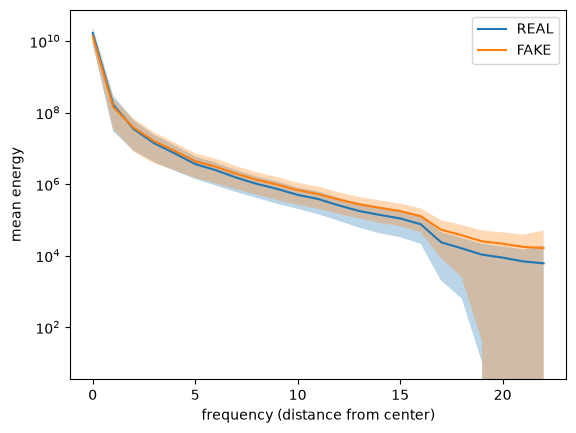

In [8]:
real = features_train[y_train == 0]
fake = features_train[y_train == 1]

mean_real = real.mean(axis=0)
mean_fake = fake.mean(axis=0)

std_real = real.std(axis=0)
std_fake = fake.std(axis=0)

x = np.arange(len(mean_real))   

plt.semilogy(x, mean_real, label="REAL")
plt.fill_between(x, mean_real - std_real, mean_real + std_real, alpha=0.3)

plt.semilogy(x, mean_fake, label="FAKE")
plt.fill_between(x, mean_fake - std_fake, mean_fake + std_fake, alpha=0.3)

plt.xlabel("frequency (distance from center)")
plt.ylabel("mean energy")
plt.legend()
plt.show()

## 6. Models

In [9]:
scaler = StandardScaler()
features_train_scaled = scaler.fit_transform(features_train)
features_val_scaled = scaler.transform(features_val)

### 6.1 Logistic Regression

In [10]:
lr = LogisticRegression(max_iter=1000)
lr.fit(features_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [11]:
pred_val = lr.predict(features_val_scaled)
score = accuracy_score(y_val, pred_val)
print("Validation accuracy (lr):", score)

Validation accuracy (lr): 0.73795


In [12]:
pred_val = lr.predict(features_val_scaled)
cm = confusion_matrix(y_val, pred_val)
print(cm)

[[7983 2017]
 [3224 6776]]


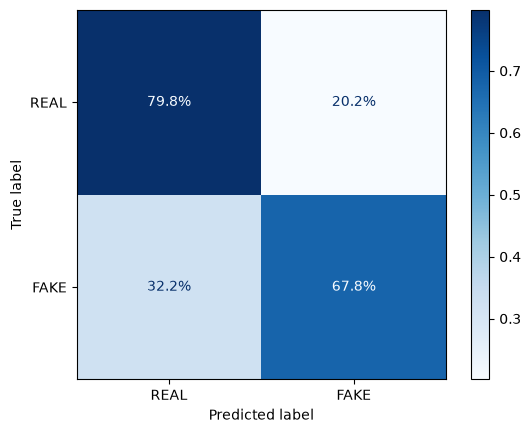

In [13]:
ConfusionMatrixDisplay.from_estimator(
    lr,
    features_val_scaled,
    y_val,
    display_labels=["REAL", "FAKE"],
    normalize="true",      
    values_format=".1%",    
    cmap=plt.cm.Blues,
)
plt.show()

### 6.2 Random Forest

In [14]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [20, 30]
}

rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=3,              
    scoring="accuracy",
    n_jobs=-1
)
rf.fit(features_train_scaled, y_train)

print("Best hyperparameters:", rf.best_params_)
print("Best cross-validation accuracy:", rf.best_score_)

Best hyperparameters: {'max_depth': 30, 'n_estimators': 200}
Best cross-validation accuracy: 0.7925125022789387


In [15]:
pred_val_rf = rf.best_estimator_.predict(features_val_scaled)
score_rf = accuracy_score(y_val, pred_val_rf)
print("Validation accuracy (rf):", score_rf)

Validation accuracy (rf): 0.79175


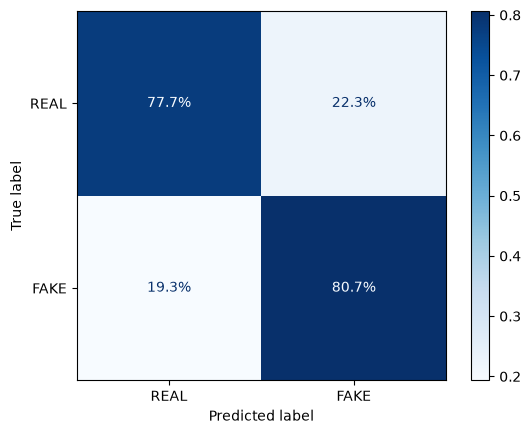

In [16]:
ConfusionMatrixDisplay.from_estimator(
    rf,
    features_val_scaled,
    y_val,
    display_labels=["REAL", "FAKE"],
    normalize="true",      
    values_format=".1%",    
    cmap=plt.cm.Blues,
)
plt.show()

### 6.3 XGBoost

In [17]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 7]
}

xgb = GridSearchCV(
    XGBClassifier(random_state=42),
    param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)
xgb.fit(features_train_scaled, y_train)

pred_val_xgb = xgb.predict(features_val_scaled)
score_xgb = accuracy_score(y_val, pred_val_xgb)
print("Validation accuracy (xgb):", score_xgb)

Validation accuracy (xgb): 0.7921


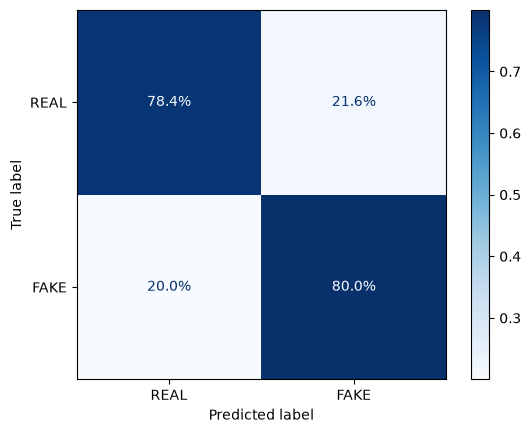

In [18]:
ConfusionMatrixDisplay.from_estimator(
    xgb,
    features_val_scaled,
    y_val,
    display_labels=["REAL", "FAKE"],
    normalize="true",      
    values_format=".1%",    
    cmap=plt.cm.Blues,
)
plt.show()

## 7. Final evaluation on the official test set

FINAL accuracy on the official test set: 0.7966


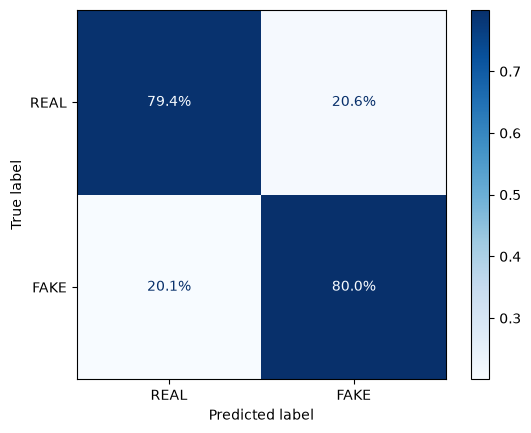

In [19]:
features_test_scaled = scaler.transform(features_test)

pred_test = xgb.predict(features_test_scaled)

score_test = accuracy_score(y_test, pred_test)
print("FINAL accuracy on the official test set:", score_test)


ConfusionMatrixDisplay.from_estimator(
    xgb, features_test_scaled, y_test,
    display_labels=["REAL", "FAKE"],
    normalize="true", 
    values_format=".1%", 
    cmap=plt.cm.Blues,
)
plt.show()

## 8. Conclusion

### Summary
Starting from the observations made in "01_Exploration", we transformed each image into its frequency spectrum. Then we summarize this 2D spectrum by taking the radial distance of each pixel (we form rings at a distance k, with k a natural number), then we average the frequencies of each ring. We thus obtain a 1D radial profile. We then use these features to train the three models: lr, rf, xgb.

### Results (validation)
| Model | Validation accuracy |
|-------|---------------------|
| Logistic Regression | 0.73795 |
| Random Forest | 0.79175 |
| XGBoost | 0.7921 |

We therefore selected XGBoost as the final model.

### Interpretation
We can therefore state that the generative model leaves a signature that is measurable in the high frequencies.

### Limitations
- The images have a low resolution, which limits the detail of the spectra.
- The dataset uses a single generation model, which can bias the results and perform worse on other generation methods.
- The features used are very simple and may not cover all the complexity of the variations between images.

### Future work
- Add richer features to improve the analysis.
- Reduce the noise with a prior denoising step.
- Compare with a different model such as a CNN.